 The archive: reading a finished run, and restarting it

Every individual a run creates stays in its SQLite database, retired ones included. `Archive` opens that file read-only and answers questions about it: who was alive in generation 12, the ten best ever, the fitness spread of the first five generations. `EA.restart` starts a new run from any recorded generation.

This notebook records a 30-generation one-max run, queries it, and then restarts it from generation 10 into a second file. The two plots show the fitness spread per generation, and the original run next to the restarted one.

In [1]:
# standard library
from pathlib import Path
from typing import cast

In [2]:
# third-party
import matplotlib.pyplot as plt

In [3]:
# local
from seachange import (
    EA,
    Archive,
    EAOperation,
    Individual,
    IntegerMutator,
    IntegersGenerator,
    Population,
    seed,
)

In [4]:
%matplotlib inline
plt.rcParams["figure.dpi"] = 72

SEED = 7
POPULATION_SIZE = 20
GENOME_LENGTH = 40
GENERATIONS = 30
RESTART_FROM = 10
TOP = 5
LOOK_AT = 12
DATA = Path("__data__")
FIRST_RUN = DATA / "first.db"
SECOND_RUN = DATA / "restarted.db"

seed(SEED)

# A run to look at

The same one-max run as in the engine notebook, on 40 bits: each generation the better half gets one mutated child each, the children are scored, and all but the best twenty are retired.

In [5]:
def random_individual() -> Individual:
    """Return an unevaluated individual with a random bit string.

    Returns
    -------
    Individual
        The new individual.
    """
    new = Individual()
    new.genotype = IntegersGenerator.integers(
        low=0, high=1, size=GENOME_LENGTH, endpoint=True
    )
    return new


def evaluate(population: Population) -> Population:
    """Score each new individual by its number of ones.

    Returns
    -------
    Population
        The same population, every member evaluated.
    """
    for member in population.unevaluated:
        member.fitness = sum(cast("list[int]", member.genotype))
    return population


def reproduce(population: Population) -> Population:
    """Add one mutated child for each individual in the better half.

    Returns
    -------
    Population
        The population with the children added.
    """
    for parent in population.best(n=POPULATION_SIZE // 2):
        child = Individual()
        child.genotype = IntegerMutator.random_reset(
            cast("list[int]", parent.genotype),
            low=0,
            high=1,
            mutation_probability=1 / GENOME_LENGTH,
        )
        population.append(child)
    return population


def retire_worst(population: Population) -> Population:
    """Mark all but the best POPULATION_SIZE individuals as dead.

    Returns
    -------
    Population
        The same population; the dead stay in the database.
    """
    for member in population.sort()[POPULATION_SIZE:]:
        member.alive = False
    return population


operations = [
    EAOperation(reproduce),
    EAOperation(evaluate),
    EAOperation(retire_worst),
]

In [6]:
first = Population([random_individual() for _ in range(POPULATION_SIZE)])
with EA(
    evaluate(first),
    operations,
    num_steps=GENERATIONS,
    db_file_path=FIRST_RUN,
    quiet=True,
) as ea:
    ea.run()
print(FIRST_RUN, "written")

__data__/first.db written


# What the archive holds

`size` counts every evaluated individual ever stored: the first twenty plus ten children per generation. `generation_range` is the span of births and deaths.

In [7]:
archive = Archive(FIRST_RUN)
print("individuals:", archive.size)
print("generations:", archive.generation_range)
assert archive.size == POPULATION_SIZE + GENERATIONS * (POPULATION_SIZE // 2)

individuals: 320
generations: first=0 last=30


# Queries

`fitness_stats` summarises the individuals born in a range of generations; `hall_of_fame` returns the best ever, alive or not; `by_generation` returns the individuals present in one generation: the twenty that survive it, and the ten retired during it (born at or before it, last stored in it).

In [8]:
early = archive.fitness_stats(birth_range=(0, 4))
late = archive.fitness_stats(birth_range=(GENERATIONS - 4, GENERATIONS))
print(f"born in generations 0-4:   mean {early.mean:.1f}, max {early.max:.0f}")
print(f"born in generations 26-30: mean {late.mean:.1f}, max {late.max:.0f}")
assert late.mean > early.mean

born in generations 0-4:   mean 23.3, max 28
born in generations 26-30: mean 32.6, max 34


In [9]:
for member in archive.hall_of_fame(n=TOP, direction="max"):
    print(
        f"fitness {member.fitness:.0f}, born {member.time_of_birth},"
        f" alive {member.alive}"
    )

fitness 34, born 26, alive True
fitness 34, born 27, alive True
fitness 34, born 28, alive True
fitness 34, born 29, alive True
fitness 34, born 30, alive True


In [10]:
present = archive.by_generation(LOOK_AT)
survivors = [m for m in present if m.alive or m.time_of_death > LOOK_AT]
print(f"present in generation {LOOK_AT}: ", len(present))
print(f"survived generation {LOOK_AT}:   ", len(survivors))
assert len(present) == POPULATION_SIZE + POPULATION_SIZE // 2
assert len(survivors) == POPULATION_SIZE

present in generation 12:  30
survived generation 12:    20


The spread of fitness among the twenty that survive each generation: the band narrows as the population converges.

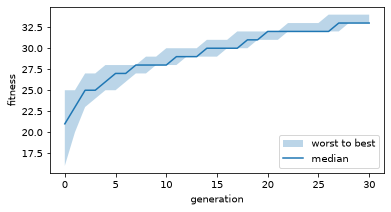

In [11]:
generations = range(GENERATIONS + 1)
spread = [
    sorted(
        m.fitness
        for m in archive.by_generation(g)
        if m.alive or m.time_of_death > g
    )
    for g in generations
]
fig, ax = plt.subplots(figsize=(6, 3))
ax.fill_between(
    generations,
    [s[0] for s in spread],
    [s[-1] for s in spread],
    alpha=0.3,
    label="worst to best",
)
ax.plot(generations, [s[len(s) // 2] for s in spread], label="median")
ax.set_xlabel("generation")
ax.set_ylabel("fitness")
ax.legend(loc="lower right")
plt.show()

# Restarting from generation 10

`EA.restart` reads the individuals alive in generation 10 of the first file and starts a new run with them in a second file; the first file is only read. The new run stores those survivors as its generation 11, unchanged, and its operations start in generation 12, so 20 steps end at generation 31. The survivors keep their birth generation, so the second file's span starts before 10. The restarted run starts where the first one was at generation 10 and then takes its own path.

In [12]:
with EA.restart(
    FIRST_RUN,
    operations,
    generation=RESTART_FROM,
    num_steps=GENERATIONS - RESTART_FROM,
    db_file_path=SECOND_RUN,
    quiet=True,
) as restarted:
    print("starts at generation", restarted.current_generation)
    restarted.run()

starts at generation 11


second run spans: first=4 last=31


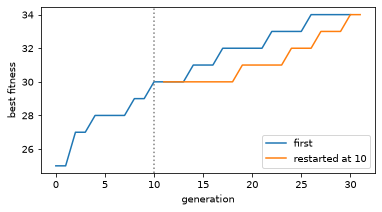

In [13]:
second = Archive(SECOND_RUN)
print("second run spans:", second.generation_range)


def best_per_generation(source: Archive, span: range) -> list[float]:
    """Return the best fitness alive in each generation of ``span``.

    Returns
    -------
    list[float]
        One value per generation.
    """
    return [max(m.fitness for m in source.by_generation(g)) for g in span]


later = range(RESTART_FROM + 1, second.generation_range.last + 1)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(generations, best_per_generation(archive, generations), label="first")
ax.plot(later, best_per_generation(second, later), label="restarted at 10")
ax.axvline(RESTART_FROM, color="grey", linestyle=":")
ax.set_xlabel("generation")
ax.set_ylabel("best fitness")
ax.legend(loc="lower right")
plt.show()

In [14]:
at_restart = best_per_generation(archive, range(RESTART_FROM, RESTART_FROM + 1))
print("best in generation 10 of the first run:", at_restart[0])
print(
    "best at the end of each run:          ",
    best_per_generation(archive, generations)[-1],
    best_per_generation(second, later)[-1],
)
assert min(best_per_generation(second, later)) >= at_restart[0]
archive.close()
second.close()

best in generation 10 of the first run: 30.0


best at the end of each run:           34.0 34.0
